
# Financial analysis - Snowflake

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv, find_dotenv
from snowflake.snowpark import Session

In [2]:
# Charge automatiquement les variables du fichier .env local
load_dotenv(find_dotenv())

connection_parameters = {
    "account": os.getenv("SNOWFLAKE_ACCOUNT"),
    "user": os.getenv("SNOWFLAKE_USER"),
    "password": os.getenv("SNOWFLAKE_PASSWORD"),
    "role": "ACCOUNTADMIN",
    "warehouse": "COMPUTE_WH",
    "database": "FINANCE_LAKEHOUSE",
    "schema": "GOLD"
}

session = Session.builder.configs(connection_parameters).create()
print("Connexion sécurisée établie avec la couche GOLD de Snowflake.")


Connexion sécurisée établie avec la couche GOLD de Snowflake.


In [3]:
query_star = """
    SELECT 
        st.SECTOR,
        st.CURRENCY,
        dt.YEAR,
        dt.QUARTER,
        COUNT(DISTINCT st.TICKER) AS NB_ACTIONS,
        SUM(f.VOLUME) AS VOLUME_TOTAL,
        ROUND(AVG(f.DAILY_RETURN_PCT), 4) AS RENDEMENT_MOYEN_PCT
    FROM GOLD.FACT_DAILY_MARKET f
    JOIN GOLD.DIM_STOCKS st ON f.STOCK_KEY = st.STOCK_KEY
    JOIN GOLD.DIM_DATE dt ON f.DATE_KEY = dt.DATE_KEY
    GROUP BY st.SECTOR, st.CURRENCY, dt.YEAR, dt.QUARTER
    ORDER BY dt.YEAR DESC, dt.QUARTER DESC, st.SECTOR
"""

df_secteurs = session.sql(query_star).to_pandas()
df_secteurs


,SECTOR,CURRENCY,YEAR,QUARTER,NB_ACTIONS,VOLUME_TOTAL,RENDEMENT_MOYEN_PCT
0,Finance,CAD,2026,4,3,403860090,0.1562
1,Finance,USD,2026,4,1,219679814,0.1519
2,Technologie,USD,2026,4,2,2148070105,0.1613
3,Finance,CAD,2026,3,3,638366700,-0.0514
4,Finance,USD,2026,3,1,499123900,0.0309
5,Technologie,USD,2026,3,2,4860982700,0.3837
6,Finance,CAD,2026,2,3,698069300,0.4593
7,Finance,USD,2026,2,1,549944300,0.1904
8,Technologie,USD,2026,2,2,5723283200,0.1336
9,Finance,CAD,2026,1,3,763405700,0.0312


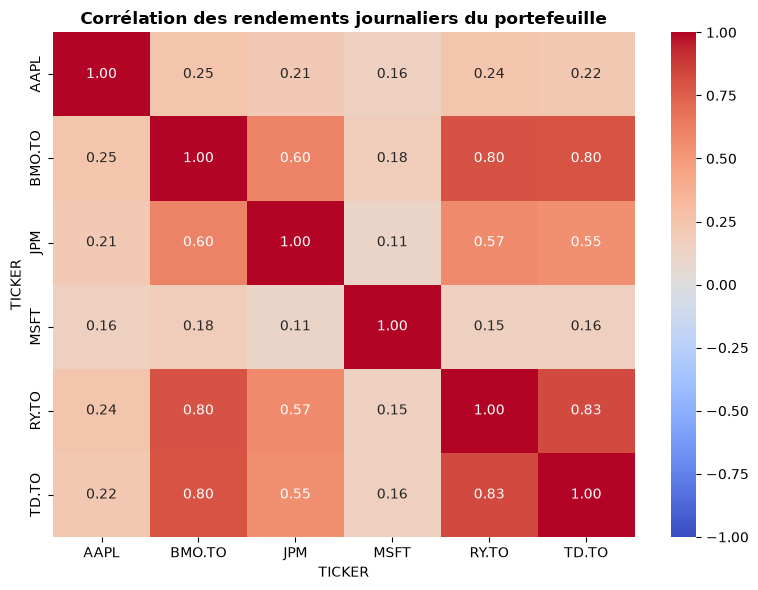

In [4]:
query_prices = """
    SELECT 
        st.TICKER,
        st.COMPANY_NAME,
        dt.FULL_DATE AS TRADE_DATE,
        f.CLOSE_PRICE,
        f.DAILY_RETURN_PCT
    FROM GOLD.FACT_DAILY_MARKET f
    JOIN GOLD.DIM_STOCKS st ON f.STOCK_KEY = st.STOCK_KEY
    JOIN GOLD.DIM_DATE dt ON f.DATE_KEY = dt.DATE_KEY
    ORDER BY st.TICKER, dt.FULL_DATE
"""

df_market = session.sql(query_prices).to_pandas()
df_market["TRADE_DATE"] = pd.to_datetime(df_market["TRADE_DATE"])

# Matrice de corrélation des rendements
pivot_returns = df_market.pivot(index="TRADE_DATE", columns="TICKER", values="DAILY_RETURN_PCT")
plt.figure(figsize=(8, 6))
sns.heatmap(pivot_returns.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Corrélation des rendements journaliers du portefeuille", fontweight="bold")
plt.tight_layout()
plt.show()


In [5]:
session.close()
print("Session Snowflake fermée.")


Session Snowflake fermée.
